# Mortality risk prediction (SUPPORT2)

We want to identify, around **day 3 of the hospital stay**, which critically ill patients are likely to **die in hospital**. Clinicians can then monitor them more closely and start goals-of-care conversations early.

This is **binary classification**:

$$
g(\underbrace{x_i}_{i\text{-th patient}}) \approx y_i \qquad y_i \in \{0, 1\}
$$

- `1`: the patient died in hospital (`hospdead = 1`), the positive class
- `0`: the patient was discharged alive

The output of the model, the score, is the probability of in-hospital death.

**Metric.** Only about 26% of the patients die, so the classes are imbalanced. Accuracy would be misleading, so we use **PR-AUC** (average precision) as the main metric and also report **ROC AUC**, as in lesson 4.

Plan (same order as the course):
1. Data preparation (3.2, 6.2)
2. Validation framework (3.3)
3. EDA (3.4)
4. Feature importance: death rate & risk ratio, mutual information, correlation (3.5-3.7)
5. One-hot encoding with `DictVectorizer` (3.8)
6. Logistic regression baseline + interpretation (3.9-3.11)
7. Evaluation: confusion table, precision & recall, ROC/PR curves (4.x)
8. Cross-validation and tuning `C` (4.7)
9. Decision tree, random forest, XGBoost and their tuning (6.3-6.8)
10. Selecting the best model and testing it (6.9)

## 1. Data preparation

### Downloading and reading the data

The dataset comes from the UCI repository ([SUPPORT2, id 880](https://archive.ics.uci.edu/dataset/880/support2)) and Kaggle ([joebeachcapital/support2](https://www.kaggle.com/datasets/joebeachcapital/support2)). A copy is committed in `data/support2.csv`. To download it again:

```bash
kaggle datasets download -d joebeachcapital/support2 -p data/ --unzip
```

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

BLUE, ORANGE, INK = '#2a78d6', '#eb6834', '#52514e'

The header of the CSV has one name fewer than the rows: the first value of each row is an unnamed row id. Pandas uses it as the index automatically. The values also have leading spaces, so we pass `skipinitialspace=True`:

In [ ]:
df = pd.read_csv('../data/support2.csv', skipinitialspace=True)
len(df)

9105

In [3]:
df.head().T

,1,2,3,4,5
age,62.84998,60.33899,52.74698,42.38498,79.88495
death,0,1,1,1,0
sex,male,female,female,female,female
hospdead,0,1,0,0,0
slos,5,4,17,3,16
d.time,2029,4,47,133,2029
dzgroup,Lung Cancer,Cirrhosis,Cirrhosis,Lung Cancer,ARF/MOSF w/Sepsis
dzclass,Cancer,COPD/CHF/Cirrhosis,COPD/CHF/Cirrhosis,Cancer,ARF/MOSF
num.co,0,2,2,2,1
edu,11.0,12.0,12.0,11.0,NaN


### Making everything uniform

In [4]:
df.columns = df.columns.str.lower().str.replace('.', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.head().T

,1,2,3,4,5
age,62.84998,60.33899,52.74698,42.38498,79.88495
death,0,1,1,1,0
sex,male,female,female,female,female
hospdead,0,1,0,0,0
slos,5,4,17,3,16
d_time,2029,4,47,133,2029
dzgroup,lung_cancer,cirrhosis,cirrhosis,lung_cancer,arf/mosf_w/sepsis
dzclass,cancer,copd/chf/cirrhosis,copd/chf/cirrhosis,cancer,arf/mosf
num_co,0,2,2,2,1
edu,11.0,12.0,12.0,11.0,NaN


In [5]:
df.dtypes

age         float64
death         int64
sex             str
hospdead      int64
slos          int64
d_time        int64
dzgroup         str
dzclass         str
num_co        int64
edu         float64
income          str
scoma       float64
charges     float64
totcst      float64
totmcst     float64
avtisst     float64
race            str
sps         float64
aps         float64
surv2m      float64
surv6m      float64
hday          int64
diabetes      int64
dementia      int64
ca              str
prg2m       float64
prg6m       float64
dnr             str
dnrday      float64
meanbp      float64
wblc        float64
hrt         float64
resp        float64
temp        float64
pafi        float64
alb         float64
bili        float64
crea        float64
sod         float64
ph          float64
glucose     float64
bun         float64
urine       float64
adlp        float64
adls        float64
sfdm2           str
adlsc       float64
dtype: object

### Removing columns that leak the target

Some columns are only known **after** the outcome, or are prognosis scores computed by the original study. If we keep them, the model will look excellent here and be useless at prediction time. We check each one by computing its AUC against the target on its own:

In [6]:
from sklearn.metrics import roc_auc_score

suspects = ['d_time', 'slos', 'charges', 'totcst', 'totmcst', 'avtisst',
            'aps', 'sps', 'surv2m', 'surv6m', 'prg2m', 'prg6m', 'dnrday']

for c in suspects:
    mask = df[c].notnull()
    auc = roc_auc_score(df.hospdead[mask], df[c][mask])
    print('%8s -> %.3f' % (c, max(auc, 1 - auc)))

  d_time -> 0.972
    slos -> 0.529
 charges -> 0.695
  totcst -> 0.690
 totmcst -> 0.687
 avtisst -> 0.834
     aps -> 0.791
     sps -> 0.787
  surv2m -> 0.841
  surv6m -> 0.811
   prg2m -> 0.814
   prg6m -> 0.780
  dnrday -> 0.582


In [7]:
df.groupby('dnr').hospdead.agg(['mean', 'count'])

,mean,count
dnr,,
dnr_after_sadm,0.618403,2956
dnr_before_sadm,0.313808,239
no_dnr,0.075340,5880


- `d_time`, `slos`, `sfdm2`, `death`: follow-up information and outcomes.
- `charges`, `totcst`, `totmcst`: cost of the **entire** hospital stay.
- `avtisst`: *average* TISS score (intensity of care) over **days 3 to 25**, which includes care given after the prediction time.
- `aps`, `sps`, `surv2m`, `surv6m`, `prg2m`, `prg6m`: existing models and physician prognoses. We keep `surv2m` aside **only as a benchmark** to compare against at the end.
- `dnr`: a DNR order written *after* admission (62% deaths) is often a consequence of the patient deteriorating. Only "DNR before admission" is known at prediction time, so we turn it into a binary flag and drop `dnrday`.
- `adlp`, `adls`: replaced by `adlsc`, the imputed combination of both.

In [8]:
df['dnr_before_adm'] = (df.dnr == 'dnr_before_sadm').astype(int)

leakage = ['death', 'd_time', 'slos', 'sfdm2', 'charges', 'totcst', 'totmcst', 'avtisst',
           'aps', 'sps', 'surv6m', 'prg2m', 'prg6m', 'dnr', 'dnrday', 'adlp', 'adls']

df = df.drop(columns=leakage)
df.shape

(9105, 31)

### Missing values and impossible values

Like `income = 99999999` in the credit-scoring data (lesson 6.2), some values are clearly errors: an albumin above 10 g/dL and a glucose below 10 mg/dL are physiologically impossible. We set them to NaN. **A heart rate, blood pressure or respiration of 0 is kept**, because it records a cardiac or respiratory arrest.

In [9]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
age,9105.0,62.65,15.59,18.04,52.80,64.86,74.00,101.85
hospdead,9105.0,0.26,0.44,0.00,0.00,0.00,1.00,1.00
num_co,9105.0,1.87,1.34,0.00,1.00,2.00,3.00,9.00
edu,7471.0,11.75,3.45,0.00,10.00,12.00,14.00,31.00
scoma,9104.0,12.06,24.64,0.00,0.00,0.00,9.00,100.00
surv2m,9104.0,0.64,0.25,0.00,0.51,0.72,0.83,0.97
hday,9105.0,4.40,9.13,1.00,1.00,1.00,3.00,148.00
diabetes,9105.0,0.20,0.40,0.00,0.00,0.00,0.00,1.00
dementia,9105.0,0.03,0.18,0.00,0.00,0.00,0.00,1.00
meanbp,9104.0,84.55,27.69,0.00,63.00,77.00,107.00,195.00


In [10]:
(df.alb > 10).sum(), (df.glucose < 10).sum()

(np.int64(2), np.int64(6))

In [11]:
df.loc[df.alb > 10, 'alb'] = np.nan
df.loc[df.glucose < 10, 'glucose'] = np.nan

In [12]:
df.isnull().sum().sort_values(ascending=False).head(15)

urine      4862
glucose    4506
bun        4352
alb        3374
income     2982
bili       2601
pafi       2325
ph         2284
edu        1634
wblc        212
crea         67
race         42
meanbp        1
resp          1
hrt           1
dtype: int64

Lab values are missing because the doctors **didn't order the test**, usually because they judged the patient stable. You can see this in the death rate:

In [13]:
for c in ['pafi', 'ph', 'wblc', 'crea', 'alb', 'bili', 'bun', 'urine', 'glucose']:
    missing = df[df[c].isnull()].hospdead.mean()
    present = df[df[c].notnull()].hospdead.mean()
    print('%8s  missing: %.3f   present: %.3f' % (c, missing, present))

    pafi  missing: 0.171   present: 0.289
      ph  missing: 0.172   present: 0.288
    wblc  missing: 0.137   present: 0.262
    crea  missing: 0.164   present: 0.260
     alb  missing: 0.260   present: 0.259
    bili  missing: 0.243   present: 0.266
     bun  missing: 0.266   present: 0.253
   urine  missing: 0.266   present: 0.251
 glucose  missing: 0.267   present: 0.252


So the authors of SUPPORT recommend filling missing labs with a **normal value** instead of 0 or the mean. We also keep a `_missing` flag for the labs that are missing most often. (We don't add flags for `ph` and `glucose`, because their missingness almost duplicates `pafi`'s and `bun`'s.)

For the categorical variables we use an explicit `unknown` category. The few NaNs left in numerical columns (`edu`, `ph`, `glucose`, ...) are filled with the **median of the training set** later, after the split.

In [14]:
for c in ['alb', 'pafi', 'bili', 'bun', 'urine']:
    df[c + '_missing'] = df[c].isnull().astype(int)

normal_values = {
    'alb': 3.5,
    'pafi': 333.3,
    'bili': 1.01,
    'crea': 1.01,
    'bun': 6.51,
    'wblc': 9.0,
    'urine': 2502.0,
}
df = df.fillna(normal_values)

for c in ['income', 'race']:
    df[c] = df[c].fillna('unknown')

In [15]:
df.isnull().sum()[df.isnull().sum() > 0]

edu        1634
scoma         1
surv2m        1
meanbp        1
hrt           1
resp          1
temp          1
sod           1
ph         2284
glucose    4506
dtype: int64

### Notes

* `pd.read_csv(..., skipinitialspace=True)` removes the spaces after each comma.
* `roc_auc_score(y, x)` of a single column against the target is a quick **leakage detector**: anything close to 1 deserves a second look.
* `df.fillna(dict)` fills each column with its own value.
* `df.loc[condition, column] = np.nan` turns impossible values into missing values.

## 2. Setting up the validation framework

60% train / 20% validation / 20% test, with `random_state=1` as in the course. We add `stratify` so that all three parts keep the same death rate, which matters because the classes are imbalanced.

In [16]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1,
                                          stratify=df.hospdead)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1,
                                    stratify=df_full_train.hospdead)

len(df_train), len(df_val), len(df_test)

(5463, 1821, 1821)

In [17]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.hospdead.values
y_val = df_val.hospdead.values
y_test = df_test.hospdead.values

# Benchmark: the SUPPORT model's own 2-month survival estimate (not a feature)
benchmark_val = 1 - df_val.surv2m.fillna(df_train.surv2m.median()).values
benchmark_test = 1 - df_test.surv2m.fillna(df_train.surv2m.median()).values

for d in [df_train, df_val, df_test]:
    del d['hospdead']
    del d['surv2m']

y_train.mean(), y_val.mean(), y_test.mean()

(np.float64(0.2591982427237781),
 np.float64(0.2591982427237781),
 np.float64(0.2591982427237781))

## 3. EDA

We do the EDA on `df_full_train` only. The test set is never looked at.

In [18]:
df_full_train = df_full_train.reset_index(drop=True)
del df_full_train['surv2m']

### Looking at the target: the death rate

In [19]:
df_full_train.hospdead.value_counts(normalize=True)

hospdead
0    0.740802
1    0.259198
Name: proportion, dtype: float64

In [20]:
global_death = df_full_train.hospdead.mean()
round(global_death, 3)

np.float64(0.259)

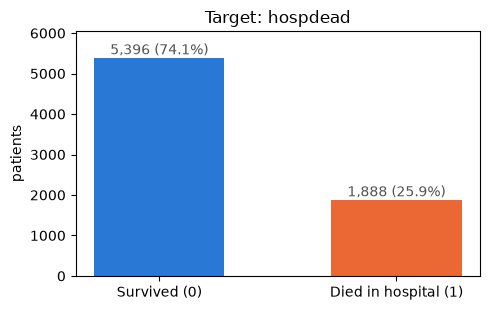

In [21]:
counts = df_full_train.hospdead.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.bar(['Survived (0)', 'Died in hospital (1)'], counts.values,
       color=[BLUE, ORANGE], width=0.55)
for i, v in enumerate(counts.values):
    ax.text(i, v + 80, f'{v:,} ({v / counts.sum():.1%})', ha='center', color=INK)
ax.set_ylabel('patients')
ax.set_ylim(0, counts.max() * 1.12)
plt.title('Target: hospdead')
plt.tight_layout()
plt.show()

The classes are **imbalanced** (≈ 26% positive), so accuracy is misleading. The primary metric is **PR-AUC**, with recall/precision at the chosen threshold, ROC-AUC and Brier score as secondary metrics. Splits are **stratified** to keep this ratio in every set.

### Numerical and categorical variables

In [22]:
categorical = ['sex', 'dzgroup', 'dzclass', 'race', 'ca', 'income']

numerical = ['age', 'num_co', 'edu', 'scoma', 'hday', 'diabetes', 'dementia',
             'meanbp', 'wblc', 'hrt', 'resp', 'temp', 'pafi', 'alb', 'bili',
             'crea', 'sod', 'ph', 'glucose', 'bun', 'urine', 'adlsc', 'dnr_before_adm',
             'alb_missing', 'pafi_missing', 'bili_missing', 'bun_missing', 'urine_missing']

len(categorical), len(numerical)

(6, 28)

In [23]:
df_full_train[categorical].nunique()

sex        2
dzgroup    8
dzclass    4
race       6
ca         3
income     5
dtype: int64

### Ranges of values

In [24]:
df_full_train[numerical].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
age,7284.0,62.75,15.58,18.04,52.95,64.87,74.11,101.85
num_co,7284.0,1.85,1.34,0.00,1.00,2.00,3.00,9.00
edu,5991.0,11.78,3.45,0.00,10.00,12.00,14.00,30.00
scoma,7283.0,12.08,24.68,0.00,0.00,0.00,9.00,100.00
hday,7284.0,4.32,8.98,1.00,1.00,1.00,3.00,148.00
diabetes,7284.0,0.19,0.40,0.00,0.00,0.00,0.00,1.00
dementia,7284.0,0.03,0.17,0.00,0.00,0.00,0.00,1.00
meanbp,7284.0,84.47,27.53,0.00,63.00,77.00,107.00,195.00
wblc,7284.0,12.29,9.34,0.00,7.00,10.40,15.10,200.00
hrt,7284.0,97.23,31.37,0.00,72.00,100.00,120.00,250.00


In [25]:
df_full_train[numerical].skew().sort_values(ascending=False).round(2)

dnr_before_adm    6.05
hday              5.90
bili              5.60
dementia          5.36
wblc              4.43
crea              3.23
bun               2.62
glucose           2.40
scoma             2.33
diabetes          1.55
pafi_missing      1.14
bili_missing      0.98
urine             0.96
adlsc             0.96
num_co            0.85
alb_missing       0.56
resp              0.51
sod               0.38
temp              0.30
meanbp            0.28
pafi              0.27
hrt               0.20
bun_missing       0.07
edu              -0.02
urine_missing    -0.14
alb              -0.47
age              -0.50
ph               -0.95
dtype: float64

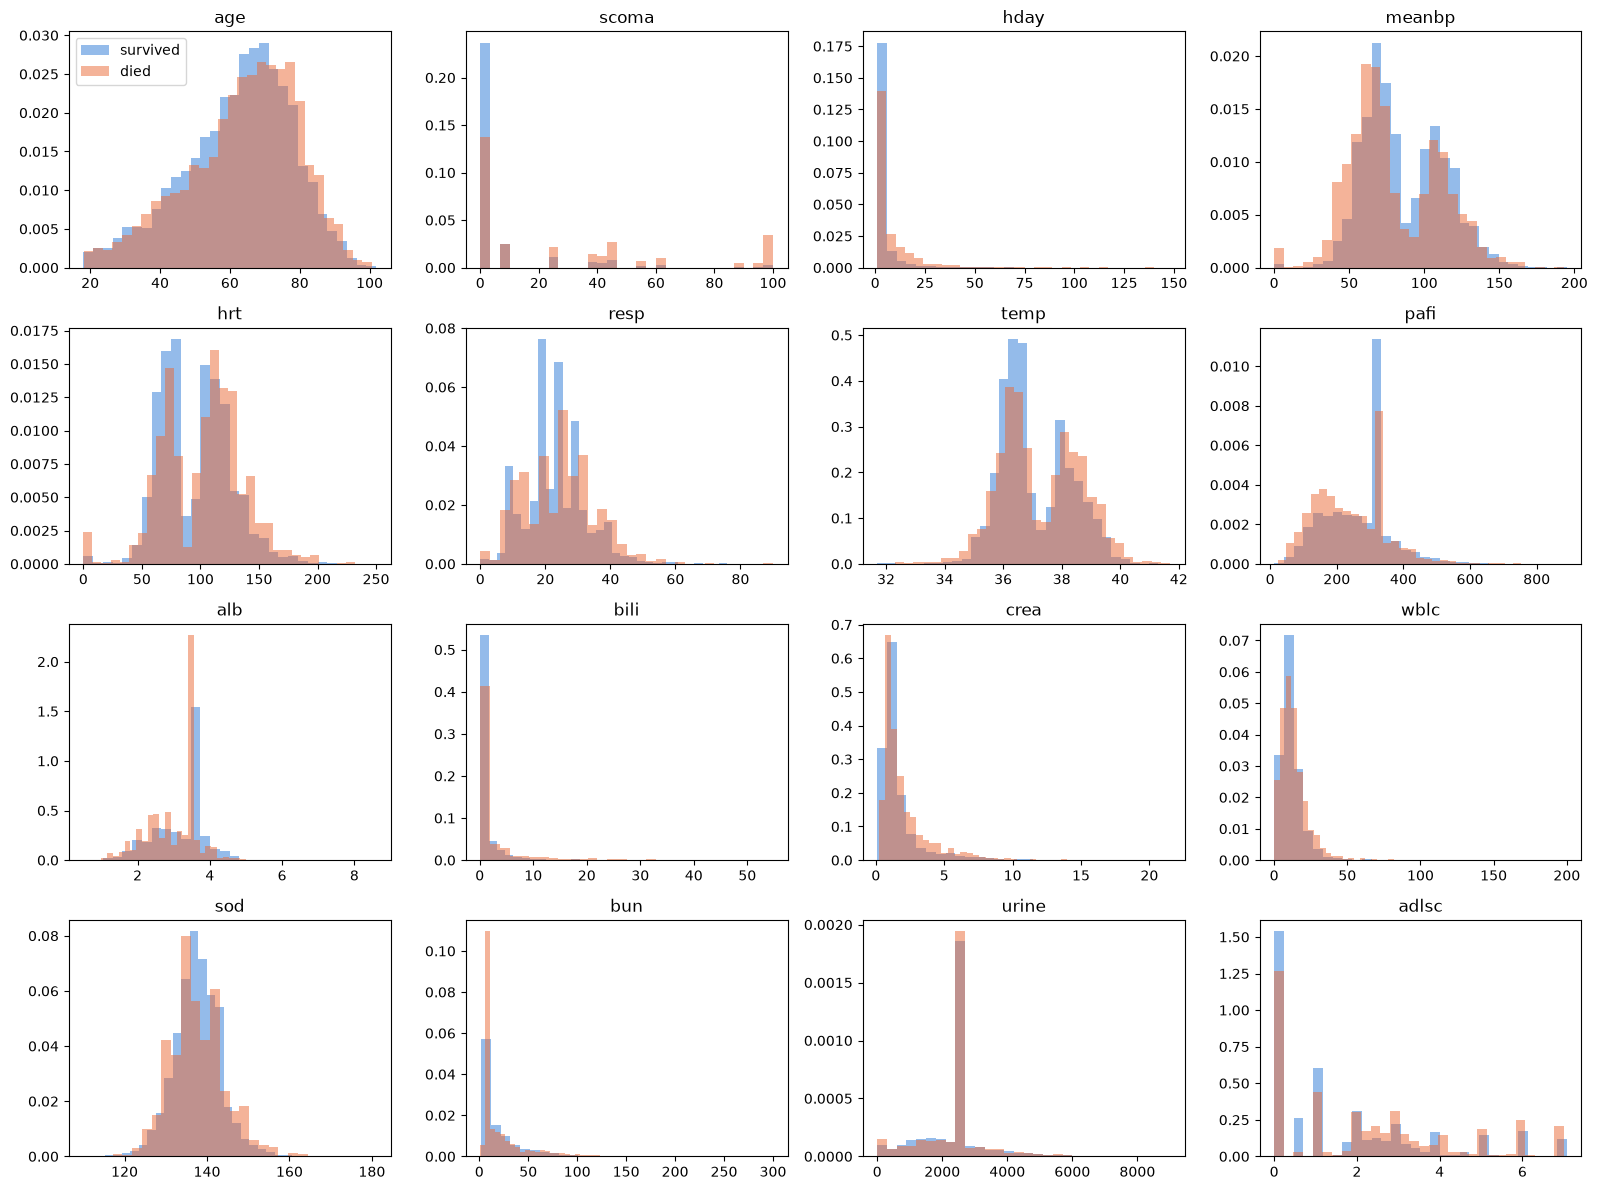

In [26]:
cols = ['age', 'scoma', 'hday', 'meanbp', 'hrt', 'resp', 'temp', 'pafi',
        'alb', 'bili', 'crea', 'wblc', 'sod', 'bun', 'urine', 'adlsc']

fig, axes = plt.subplots(4, 4, figsize=(16, 12))

for ax, c in zip(axes.flat, cols):
    ax.hist(df_full_train[df_full_train.hospdead == 0][c], bins=30, density=True,
            alpha=0.5, color=BLUE, label='survived')
    ax.hist(df_full_train[df_full_train.hospdead == 1][c], bins=30, density=True,
            alpha=0.5, color=ORANGE, label='died')
    ax.set_title(c)

axes.flat[0].legend()
plt.tight_layout()
plt.show()

- `bili`, `crea`, `bun`, `wblc`, `hday` are long-tailed, like `price` in lesson 2. We keep the extreme values (a bilirubin of 60 is real in liver failure) and use `np.log1p` for them in the linear model. Trees don't need it.
- The peaks at 3.5 (`alb`), 333 (`pafi`) and 2502 (`urine`) come from the normal-value fill.
- Patients who died have a higher coma score (`scoma`), a longer stay before day 3 (`hday`) and worse functional status (`adlsc`), and a lower `pafi` and `meanbp`.

### Text features

SUPPORT2 has **no free-text columns**. All the string columns are short category labels (`dzgroup`, `income`, ...), so frequent words and word clouds don't apply. We analyse them as categorical variables in the next section.

### Notes

* `df.x.value_counts(normalize=True)` gives the share of each class: 74% survived, 26% died. The mean of a 0/1 target equals the positive rate.
* `df.describe()` shows the **ranges** and `df.skew()` shows which variables have long tails.

## 4. Feature importance

### Death rate and risk ratio

Same idea as the churn rate in lesson 3.5: compare each group's death rate with the global one.
- `diff = group - global`: > 0 means a higher risk
- `risk = group / global`: > 1 means a higher risk

In [27]:
for c in categorical:
    print(c)
    df_group = df_full_train.groupby(c).hospdead.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_death
    df_group['risk'] = df_group['mean'] / global_death
    display(df_group.sort_values('risk', ascending=False).round(3))
    print()

sex


,mean,count,diff,risk
sex,,,,
female,0.269,3192,0.010,1.037
male,0.252,4092,-0.007,0.971



dzgroup


,mean,count,diff,risk
dzgroup,,,,
coma,0.624,482,0.365,2.409
mosf_w/malig,0.525,568,0.265,2.024
arf/mosf_w/sepsis,0.333,2817,0.074,1.286
cirrhosis,0.227,410,-0.032,0.875
copd,0.114,779,-0.145,0.441
lung_cancer,0.114,720,-0.145,0.439
chf,0.059,1088,-0.200,0.227
colon_cancer,0.052,420,-0.207,0.202



dzclass


,mean,count,diff,risk
dzclass,,,,
coma,0.624,482,0.365,2.409
arf/mosf,0.365,3385,0.106,1.410
copd/chf/cirrhosis,0.108,2277,-0.151,0.417
cancer,0.091,1140,-0.168,0.352


... (2 outputs left out)


ca


,mean,count,diff,risk
ca,,,,
yes,0.368,1024,0.109,1.420
no,0.262,4766,0.003,1.010
metastatic,0.176,1494,-0.083,0.679



income


,mean,count,diff,risk
income,,,,
unknown,0.298,2391,0.039,1.150
under_$11k,0.247,2279,-0.012,0.955
$25-$50k,0.235,841,-0.024,0.908
$11-$25k,0.234,1224,-0.025,0.905
>$50k,0.230,549,-0.030,0.885


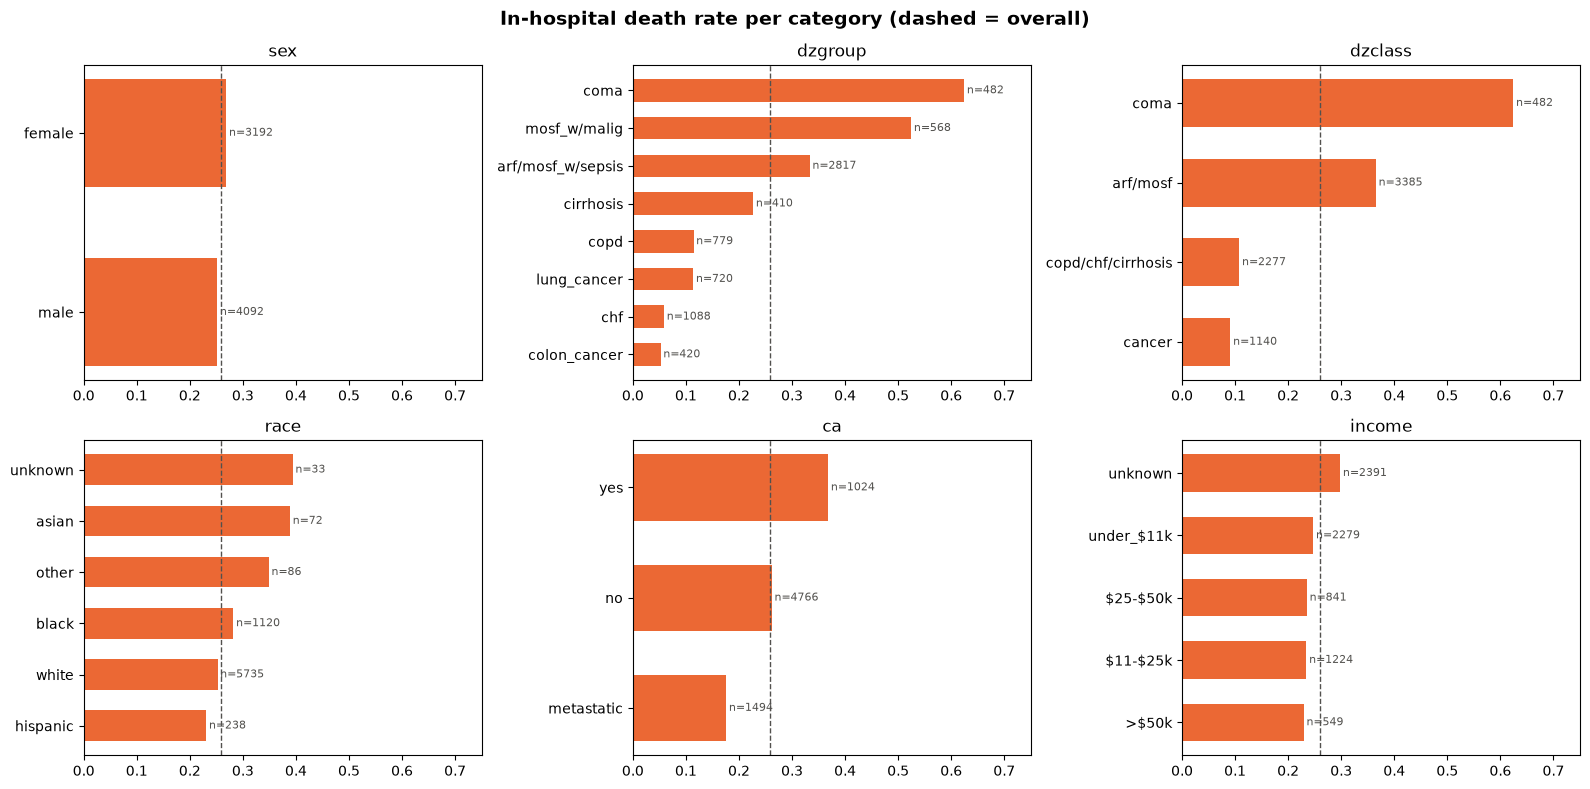

In [28]:
plt.rcParams['text.parse_math'] = False   # income labels contain '$'

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.flat, categorical):
    g = df_full_train.groupby(c).hospdead.agg(['count', 'mean']).sort_values('mean')
    ax.barh(g.index, g['mean'], color=ORANGE, height=0.6)
    ax.axvline(global_death, color=INK, ls='--', lw=1)
    for y, (n, m) in enumerate(zip(g['count'], g['mean'])):
        ax.text(m + 0.005, y, f'n={n}', va='center', fontsize=8, color=INK)
    ax.set_title(c); ax.set_xlim(0, max(0.75, g['mean'].max() + 0.12))
fig.suptitle('In-hospital death rate per category (dashed = overall)', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

- `dzgroup`: **coma** (risk ≈ 2.3) and **MOSF with malignancy** (≈ 2.2) are the most dangerous groups. **Colon cancer**, **CHF** and **COPD** are the safest.
- `ca`: interesting. A non-metastatic cancer (`yes`) raises the risk, but `metastatic` *lowers* it. These patients tend to die later, outside the hospital, and the target only counts in-hospital deaths.
- `sex`, `race`, `income`: close to 1, so they have little effect.

### Mutual information

In [29]:
from sklearn.metrics import mutual_info_score

def mutual_info_death_score(series):
    return mutual_info_score(series, df_full_train.hospdead)

mi = df_full_train[categorical].apply(mutual_info_death_score)
mi.sort_values(ascending=False)

dzgroup    0.079853
dzclass    0.068518
ca         0.008054
income     0.001999
race       0.001203
sex        0.000187
dtype: float64

### Correlation

In [30]:
df_full_train[numerical].corrwith(df_full_train.hospdead).sort_values()

pafi             -0.134260
pafi_missing     -0.122298
alb              -0.110449
meanbp           -0.098489
num_co           -0.083428
ph               -0.041509
bili_missing     -0.024256
diabetes         -0.013651
alb_missing      -0.002401
urine            -0.000766
bun               0.014463
bun_missing       0.015810
edu               0.017180
urine_missing     0.020019
glucose           0.021410
dnr_before_adm    0.024573
sod               0.026776
resp              0.027094
dementia          0.040105
age               0.042122
temp              0.068075
wblc              0.068474
crea              0.097319
hrt               0.099463
adlsc             0.129098
bili              0.148752
hday              0.218219
scoma             0.387768
dtype: float64

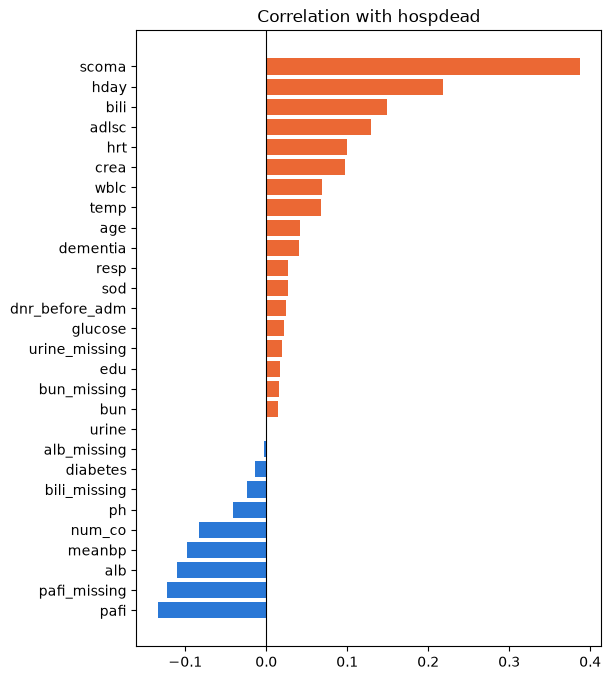

In [31]:
corr = df_full_train[numerical].corrwith(df_full_train.hospdead).sort_values()

plt.figure(figsize=(6, 8))
plt.barh(corr.index, corr.values, color=[ORANGE if v > 0 else BLUE for v in corr.values])
plt.axvline(0, color='black', lw=0.8)
plt.title('Correlation with hospdead')
plt.show()

Checking the relationship with groups, as was done for `tenure` in lesson 3.7:

In [32]:
df_full_train[df_full_train.scoma == 0].hospdead.mean(), \
df_full_train[(df_full_train.scoma > 0) & (df_full_train.scoma <= 40)].hospdead.mean(), \
df_full_train[df_full_train.scoma > 40].hospdead.mean()

(np.float64(0.16829363529871144),
 np.float64(0.3350970017636684),
 np.float64(0.6280428432327166))

In [33]:
df_full_train[df_full_train.age <= 50].hospdead.mean(), \
df_full_train[(df_full_train.age > 50) & (df_full_train.age <= 75)].hospdead.mean(), \
df_full_train[df_full_train.age > 75].hospdead.mean()

(np.float64(0.25166889185580776),
 np.float64(0.2445308701993194),
 np.float64(0.3020334928229665))

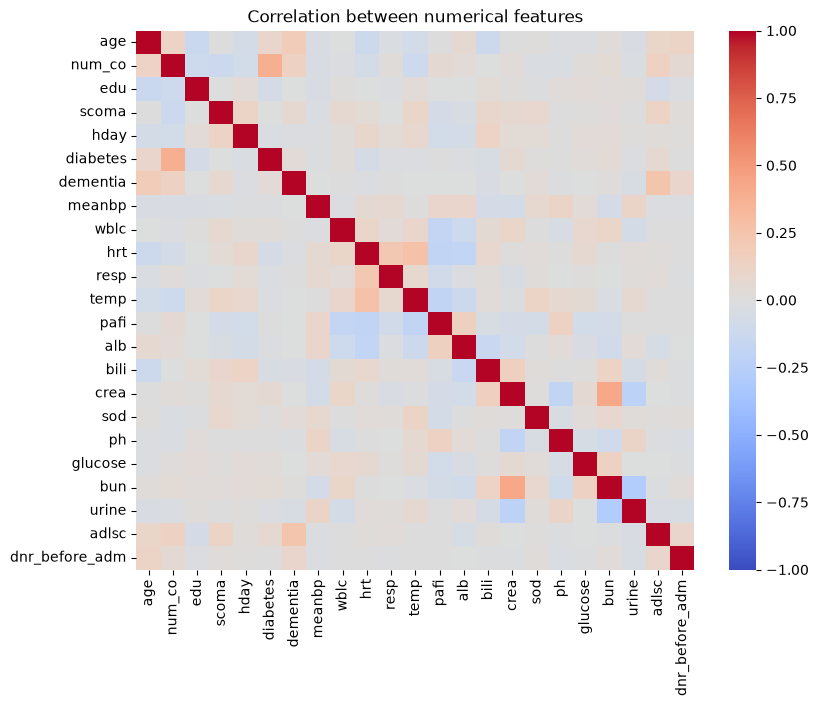

In [34]:
plt.figure(figsize=(9, 7))
sns.heatmap(df_full_train[numerical[:23]].corr(), cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation between numerical features')
plt.show()

### Notes

* The **risk ratio** and **mutual information** both show that the diagnosis (`dzgroup` / `dzclass`) is the most important categorical variable.
* `scoma` (coma score) has the highest correlation with the target: patients with `scoma > 40` die far more often than those with `scoma = 0`.
* No pair of numerical features is so correlated (|r| > 0.9) that we need to drop one.

## 5. One-hot encoding

We use `DictVectorizer`, as in lesson 3.8. The remaining NaNs (`edu`, `ph`, `glucose`, ...) are filled with the **train** medians first.

In [35]:
from sklearn.feature_extraction import DictVectorizer

medians = df_train[numerical].median()

def prepare_dicts(df, medians, log=False):
    df = df[categorical + numerical].copy()
    df[numerical] = df[numerical].fillna(medians)
    if log:
        for c in ['bili', 'crea', 'bun', 'wblc', 'glucose', 'urine', 'hday']:
            df[c] = np.log1p(df[c])
    return df.to_dict(orient='records')

In [36]:
train_dicts = prepare_dicts(df_train, medians)
train_dicts[0]

{'sex': 'male',
 'dzgroup': 'chf',
 'dzclass': 'copd/chf/cirrhosis',
 'race': 'white',
 'ca': 'no',
 'income': '>$50k',
 'age': 53.50299,
 'num_co': 2,
 'edu': 14.0,
 'scoma': 0.0,
 'hday': 1,
 'diabetes': 0,
 'dementia': 0,
 'meanbp': 63.0,
 'wblc': 12.6992188,
 'hrt': 125.0,
 'resp': 26.0,
 'temp': 39.09375,
 'pafi': 333.3,
 'alb': 3.699707,
 'bili': 1.29980469,
 'crea': 1.29980469,
 'sod': 138.0,
 'ph': 7.429688,
 'glucose': 154.0,
 'bun': 14.0,
 'urine': 2670.0,
 'adlsc': 0.0,
 'dnr_before_adm': 0,
 'alb_missing': 0,
 'pafi_missing': 1,
 'bili_missing': 0,
 'bun_missing': 0,
 'urine_missing': 0}

In [37]:
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)

val_dicts = prepare_dicts(df_val, medians)
X_val = dv.transform(val_dicts)

X_train.shape, X_val.shape

((5463, 56), (1821, 56))

In [38]:
dv.get_feature_names_out()

array(['adlsc', 'age', 'alb', 'alb_missing', 'bili', 'bili_missing',
       'bun', 'bun_missing', 'ca=metastatic', 'ca=no', 'ca=yes', 'crea',
       'dementia', 'diabetes', 'dnr_before_adm', 'dzclass=arf/mosf',
       'dzclass=cancer', 'dzclass=coma', 'dzclass=copd/chf/cirrhosis',
       'dzgroup=arf/mosf_w/sepsis', 'dzgroup=chf', 'dzgroup=cirrhosis',
       'dzgroup=colon_cancer', 'dzgroup=coma', 'dzgroup=copd',
       'dzgroup=lung_cancer', 'dzgroup=mosf_w/malig', 'edu', 'glucose',
       'hday', 'hrt', 'income=$11-$25k', 'income=$25-$50k',
       'income=>$50k', 'income=under_$11k', 'income=unknown', 'meanbp',
       'num_co', 'pafi', 'pafi_missing', 'ph', 'race=asian', 'race=black',
       'race=hispanic', 'race=other', 'race=unknown', 'race=white',
       'resp', 'scoma', 'sex=female', 'sex=male', 'sod', 'temp', 'urine',
       'urine_missing', 'wblc'], dtype=object)

## 6. Logistic regression (baseline)

For the linear model we use the `log1p` version of the skewed variables.

In [39]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

dv_lr = DictVectorizer(sparse=False)
X_train_lr = dv_lr.fit_transform(prepare_dicts(df_train, medians, log=True))
X_val_lr = dv_lr.transform(prepare_dicts(df_val, medians, log=True))

model = LogisticRegression(solver='lbfgs', C=1.0, max_iter=5000)
model.fit(X_train_lr, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",5000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [40]:
y_pred = model.predict_proba(X_val_lr)[:, 1]

print('PR-AUC  %.3f' % average_precision_score(y_val, y_pred))
print('ROC AUC %.3f' % roc_auc_score(y_val, y_pred))

PR-AUC  0.623
ROC AUC 0.816


In [41]:
death_decision = (y_pred >= 0.5)
(y_val == death_decision).mean()

np.float64(0.7891268533772653)

### Model interpretation

The coefficients show which features push the risk up (+) or down (-):

In [42]:
coef = pd.Series(model.coef_[0], index=dv_lr.get_feature_names_out()).sort_values()
pd.concat([coef.head(8), coef.tail(8)]).round(3)

dzgroup=chf                  -0.660
bun_missing                  -0.502
ph                           -0.386
dzgroup=colon_cancer         -0.355
dzclass=copd/chf/cirrhosis   -0.341
race=hispanic                -0.291
bun                          -0.241
dzclass=cancer               -0.227
bili                          0.367
hday                          0.370
urine_missing                 0.403
dzgroup=cirrhosis             0.530
dzclass=arf/mosf              0.572
crea                          0.587
race=unknown                  0.627
dzgroup=mosf_w/malig          0.741
dtype: float64

## 7. Evaluation

### Accuracy and the dummy model

In [43]:
from sklearn.metrics import accuracy_score

thresholds = np.linspace(0, 1, 21)
scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    scores.append(score)
    print('%.2f %.3f' % (t, score))

0.00 0.259
0.05 0.375
0.10 0.558
0.15 0.646
0.20 0.688
0.25 0.730
0.30 0.752
0.35 0.776
0.40 0.780
0.45 0.791
0.50 0.789
0.55 0.797
0.60 0.797
0.65 0.792
0.70 0.786
0.75 0.780
0.80 0.773
0.85 0.764
0.90 0.750
0.95 0.743
1.00 0.741


In [44]:
# A dummy model that predicts "survived" for everyone
1 - y_val.mean()

np.float64(0.7408017572762219)

A model that always predicts "survived" already gets about 74% accuracy, so accuracy is not a useful metric here.

### Confusion table, precision and recall

In [45]:
t = 0.5

actual_positive = (y_val == 1)
actual_negative = (y_val == 0)
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()
fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
confusion_matrix

array([[1224,  125],
       [ 259,  213]])

In [46]:
p = tp / (tp + fp)
r = tp / (tp + fn)
p, r

(np.float64(0.6301775147928994), np.float64(0.451271186440678))

At `t = 0.5` the model misses many patients who die (low recall). In this problem a **false negative** (a high-risk patient who is not flagged) is the costly error, so later we pick a lower threshold.

### Precision and recall at all thresholds

In [47]:
def pr_dataframe(y_val, y_pred):
    scores = []
    for t in np.linspace(0, 1, 101):
        tp = ((y_pred >= t) & (y_val == 1)).sum()
        fp = ((y_pred >= t) & (y_val == 0)).sum()
        fn = ((y_pred < t) & (y_val == 1)).sum()
        tn = ((y_pred < t) & (y_val == 0)).sum()
        scores.append((t, tp, fp, fn, tn))

    df_scores = pd.DataFrame(scores, columns=['threshold', 'tp', 'fp', 'fn', 'tn'])
    df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)
    df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)
    return df_scores

df_scores = pr_dataframe(y_val, y_pred)
df_scores[::10]

,threshold,tp,fp,fn,tn,precision,recall,fpr
0,0.0,472,1349,0,0,0.259198,1.000000,1.000000
10,0.1,442,775,30,574,0.363188,0.936441,0.574500
20,0.2,385,481,87,868,0.444573,0.815678,0.356560
30,0.3,325,304,147,1045,0.516693,0.688559,0.225352
40,0.4,259,187,213,1162,0.580717,0.548729,0.138621
50,0.5,213,125,259,1224,0.630178,0.451271,0.092661
60,0.6,172,70,300,1279,0.710744,0.364407,0.051890
70,0.7,117,35,355,1314,0.769737,0.247881,0.025945
80,0.8,71,12,401,1337,0.855422,0.150424,0.008895
90,0.9,20,3,452,1346,0.869565,0.042373,0.002224


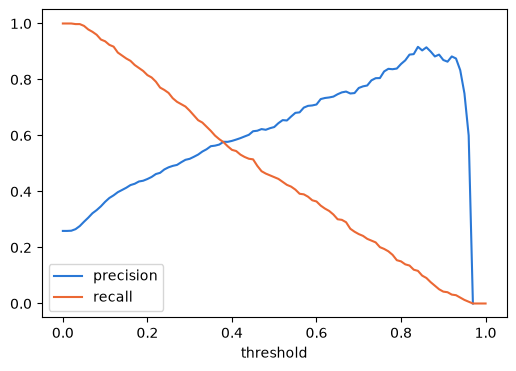

In [48]:
plt.figure(figsize=(6, 4))
plt.plot(df_scores.threshold, df_scores.precision, color=BLUE, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, color=ORANGE, label='recall')
plt.xlabel('threshold')
plt.legend()
plt.show()

### ROC and PR curves

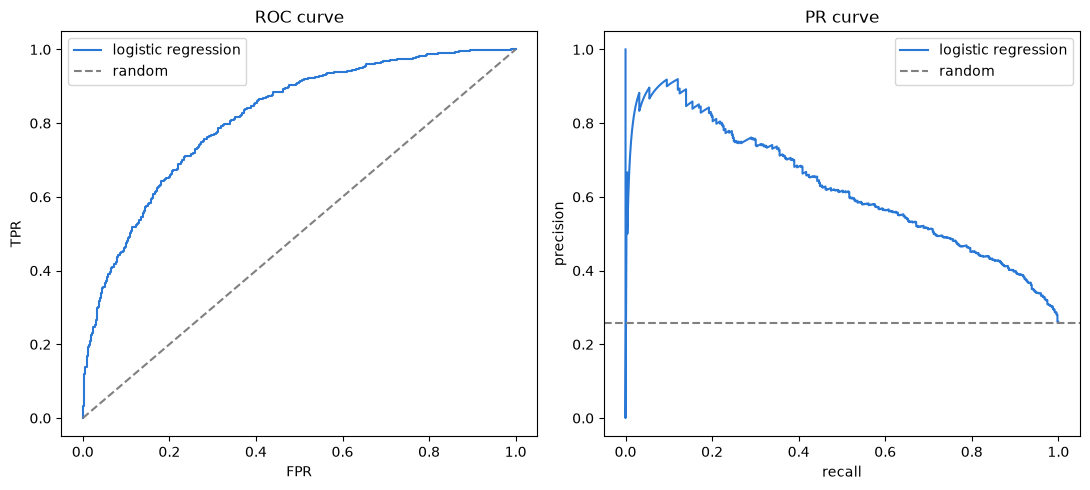

In [49]:
from sklearn.metrics import roc_curve, precision_recall_curve

fpr, tpr, _ = roc_curve(y_val, y_pred)
prec, rec, _ = precision_recall_curve(y_val, y_pred)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))

ax1.plot(fpr, tpr, color=BLUE, label='logistic regression')
ax1.plot([0, 1], [0, 1], color='grey', linestyle='--', label='random')
ax1.set_xlabel('FPR'); ax1.set_ylabel('TPR'); ax1.set_title('ROC curve'); ax1.legend()

ax2.plot(rec, prec, color=BLUE, label='logistic regression')
ax2.axhline(y_val.mean(), color='grey', linestyle='--', label='random')
ax2.set_xlabel('recall'); ax2.set_ylabel('precision'); ax2.set_title('PR curve'); ax2.legend()

plt.tight_layout()
plt.show()

### Notes

* With imbalanced classes, the random baseline of the **PR curve** is the positive rate (≈ 0.26), not 0.5 as for ROC.
* **PR-AUC** focuses on how well we find the patients who die, so it is our main metric. **ROC AUC** is kept so the results can be compared with the medical literature.

## 8. Cross-validation: tuning `C`

As in lesson 4.7, with `StratifiedKFold` so each fold keeps the 26% death rate.

In [50]:
from sklearn.model_selection import StratifiedKFold

def train(df_train, y_train, C=1.0):
    medians = df_train[numerical].median()
    dicts = prepare_dicts(df_train, medians, log=True)

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(C=C, max_iter=5000)
    model.fit(X_train, y_train)

    return dv, medians, model


def predict(df, dv, medians, model):
    dicts = prepare_dicts(df, medians, log=True)
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]

In [51]:
n_splits = 5

for C in [0.001, 0.01, 0.1, 0.5, 1, 5, 10]:
    kfold = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train, df_full_train.hospdead):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        y_tr = df_tr.hospdead.values
        y_va = df_va.hospdead.values

        dv_cv, medians_cv, model_cv = train(df_tr, y_tr, C=C)
        y_pred_cv = predict(df_va, dv_cv, medians_cv, model_cv)

        scores.append(average_precision_score(y_va, y_pred_cv))

    print('C=%5s  PR-AUC %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

C=0.001  PR-AUC 0.606 +- 0.016


C= 0.01  PR-AUC 0.626 +- 0.018


C=  0.1  PR-AUC 0.630 +- 0.017


C=  0.5  PR-AUC 0.629 +- 0.016


C=    1  PR-AUC 0.629 +- 0.016


C=    5  PR-AUC 0.629 +- 0.016


C=   10  PR-AUC 0.630 +- 0.016


In [52]:
C = 0.1

dv_lr, medians_lr, model_lr = train(df_train, y_train, C=C)
y_pred_lr = predict(df_val, dv_lr, medians_lr, model_lr)

print('LR  PR-AUC %.3f  ROC AUC %.3f' % (average_precision_score(y_val, y_pred_lr),
                                        roc_auc_score(y_val, y_pred_lr)))

LR  PR-AUC 0.625  ROC AUC 0.817


## 9. Decision trees

From here on we use `X_train` / `X_val` (no log transform), like lesson 6.3.

In [53]:
from sklearn.tree import DecisionTreeClassifier, export_text

dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)

y_pred = dt.predict_proba(X_train)[:, 1]
print('train', roc_auc_score(y_train, y_pred))

y_pred = dt.predict_proba(X_val)[:, 1]
print('val  ', roc_auc_score(y_val, y_pred))

train 1.0
val   0.6330819439383849


Training AUC is 1.0 but validation AUC is much lower, so the tree is **overfitting**. A tree with depth 2 looks like this:

In [54]:
dt = DecisionTreeClassifier(max_depth=2)
dt.fit(X_train, y_train)

print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- scoma <= 17.50
|   |--- dzclass=arf/mosf <= 0.50
|   |   |--- class: 0
|   |--- dzclass=arf/mosf >  0.50
|   |   |--- class: 0
|--- scoma >  17.50
|   |--- scoma <= 75.00
|   |   |--- class: 0
|   |--- scoma >  75.00
|   |   |--- class: 1



### Tuning `max_depth`

In [55]:
depths = [1, 2, 3, 4, 5, 6, 10, 15, 20, None]

for depth in depths:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=1)
    dt.fit(X_train, y_train)

    y_pred = dt.predict_proba(X_val)[:, 1]
    print('%4s -> PR-AUC %.3f  ROC AUC %.3f' % (depth, average_precision_score(y_val, y_pred),
                                               roc_auc_score(y_val, y_pred)))

   1 -> PR-AUC 0.406  ROC AUC 0.676
   2 -> PR-AUC 0.489  ROC AUC 0.759
   3 -> PR-AUC 0.508  ROC AUC 0.761
   4 -> PR-AUC 0.542  ROC AUC 0.776
   5 -> PR-AUC 0.545  ROC AUC 0.781


   6 -> PR-AUC 0.538  ROC AUC 0.769
  10 -> PR-AUC 0.443  ROC AUC 0.682
  15 -> PR-AUC 0.394  ROC AUC 0.608


  20 -> PR-AUC 0.357  ROC AUC 0.597
None -> PR-AUC 0.360  ROC AUC 0.645


### Tuning `min_samples_leaf`

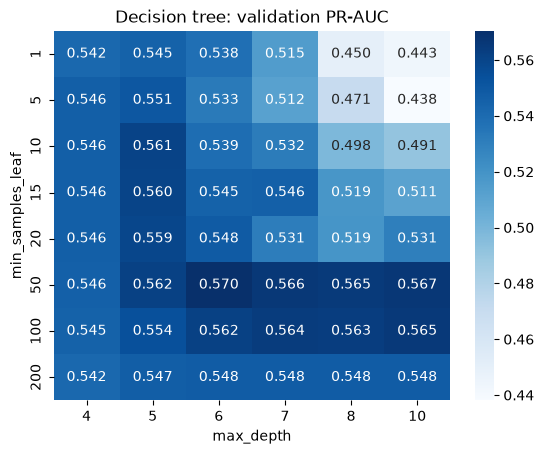

In [56]:
scores = []

for depth in [4, 5, 6, 7, 8, 10]:
    for s in [1, 5, 10, 15, 20, 50, 100, 200]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=s, random_state=1)
        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:, 1]
        scores.append((depth, s, average_precision_score(y_val, y_pred)))

columns = ['max_depth', 'min_samples_leaf', 'pr_auc']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns='max_depth', values='pr_auc')
sns.heatmap(df_scores_pivot, annot=True, fmt='.3f', cmap='Blues')
plt.title('Decision tree: validation PR-AUC')
plt.show()

In [57]:
best = df_scores.sort_values('pr_auc', ascending=False).iloc[0]
dt_max_depth, dt_min_samples_leaf = int(best.max_depth), int(best.min_samples_leaf)
best

max_depth            6.000000
min_samples_leaf    50.000000
pr_auc               0.570429
Name: 21, dtype: float64

In [58]:
dt = DecisionTreeClassifier(max_depth=dt_max_depth, min_samples_leaf=dt_min_samples_leaf,
                            random_state=1)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict_proba(X_val)[:, 1]

## 9.1 Random forest

### Tuning `n_estimators`

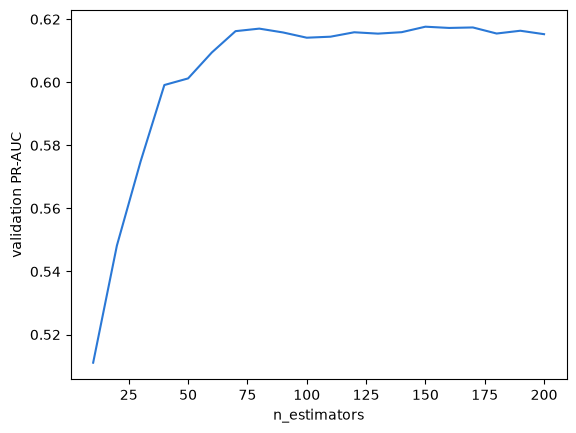

In [59]:
from sklearn.ensemble import RandomForestClassifier

scores = []

for n in range(10, 201, 10):
    rf = RandomForestClassifier(n_estimators=n, random_state=1, n_jobs=-1)
    rf.fit(X_train, y_train)

    y_pred = rf.predict_proba(X_val)[:, 1]
    scores.append((n, average_precision_score(y_val, y_pred)))

df_scores = pd.DataFrame(scores, columns=['n_estimators', 'pr_auc'])

plt.plot(df_scores.n_estimators, df_scores.pr_auc, color=BLUE)
plt.xlabel('n_estimators'); plt.ylabel('validation PR-AUC')
plt.show()

### Tuning `max_depth`

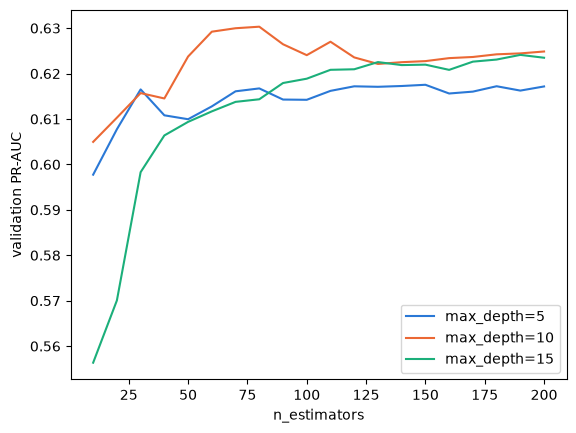

In [60]:
scores = []

for d in [5, 10, 15]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        scores.append((d, n, average_precision_score(y_val, y_pred)))

df_scores = pd.DataFrame(scores, columns=['max_depth', 'n_estimators', 'pr_auc'])

for d, color in zip([5, 10, 15], [BLUE, ORANGE, '#1baf7a']):
    df_subset = df_scores[df_scores.max_depth == d]
    plt.plot(df_subset.n_estimators, df_subset.pr_auc, color=color, label='max_depth=%d' % d)

plt.xlabel('n_estimators'); plt.ylabel('validation PR-AUC')
plt.legend()
plt.show()

In [61]:
rf_max_depth = int(df_scores.groupby('max_depth').pr_auc.mean().idxmax())
rf_max_depth

10

### Tuning `min_samples_leaf`

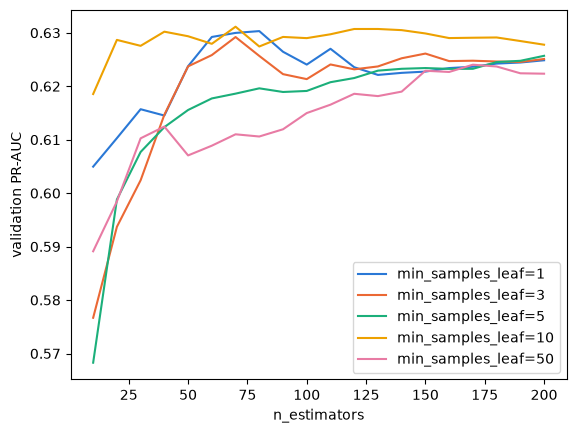

In [62]:
scores = []

for s in [1, 3, 5, 10, 50]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n, max_depth=rf_max_depth,
                                    min_samples_leaf=s, random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        scores.append((s, n, average_precision_score(y_val, y_pred)))

df_scores = pd.DataFrame(scores, columns=['min_samples_leaf', 'n_estimators', 'pr_auc'])

for s, color in zip([1, 3, 5, 10, 50], [BLUE, ORANGE, '#1baf7a', '#eda100', '#e87ba4']):
    df_subset = df_scores[df_scores.min_samples_leaf == s]
    plt.plot(df_subset.n_estimators, df_subset.pr_auc, color=color, label='min_samples_leaf=%d' % s)

plt.xlabel('n_estimators'); plt.ylabel('validation PR-AUC')
plt.legend()
plt.show()

In [63]:
rf_min_samples_leaf = int(df_scores.groupby('min_samples_leaf').pr_auc.mean().idxmax())
rf_min_samples_leaf

10

In [64]:
rf = RandomForestClassifier(n_estimators=200, max_depth=rf_max_depth,
                            min_samples_leaf=rf_min_samples_leaf, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict_proba(X_val)[:, 1]

## 9.2 Gradient boosting with XGBoost

We monitor `aucpr` (the PR-AUC) on train and validation at each boosting round.

In [65]:
import xgboost as xgb
from IPython.utils.capture import capture_output

features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

watchlist = [(dtrain, 'train'), (dval, 'val')]

In [66]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))

    columns = ['num_iter', 'train_aucpr', 'val_aucpr']
    return pd.DataFrame(results, columns=columns)


def train_xgb(eta=0.3, max_depth=6, min_child_weight=1, num_boost_round=200):
    xgb_params = {
        'eta': eta,
        'max_depth': max_depth,
        'min_child_weight': min_child_weight,

        'objective': 'binary:logistic',
        'eval_metric': 'aucpr',

        'nthread': 8,
        'seed': 1,
        'verbosity': 1,
    }
    with capture_output() as output:
        model = xgb.train(xgb_params, dtrain, num_boost_round=num_boost_round,
                          verbose_eval=5, evals=watchlist)
    return model, parse_xgb_output(output)

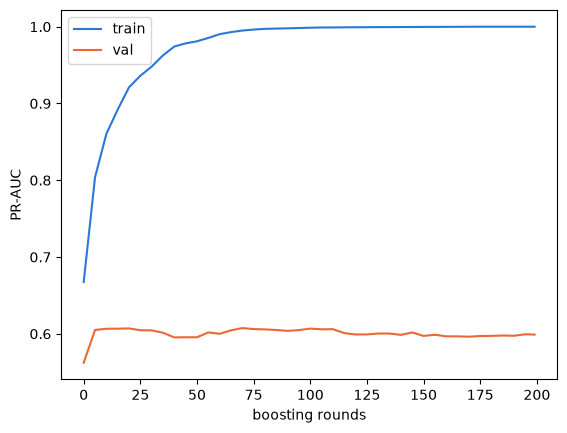

In [67]:
model, df_score = train_xgb()

plt.plot(df_score.num_iter, df_score.train_aucpr, color=BLUE, label='train')
plt.plot(df_score.num_iter, df_score.val_aucpr, color=ORANGE, label='val')
plt.xlabel('boosting rounds'); plt.ylabel('PR-AUC')
plt.legend()
plt.show()

With the default `eta=0.3` the model overfits quickly: training PR-AUC climbs to about 1.0 while validation PR-AUC stays flat at about 0.60 from round 5 onwards.

### Tuning `eta`

In [68]:
def plot_scores(scores, title):
    plt.figure(figsize=(7, 4))
    for key, df_score in scores.items():
        plt.plot(df_score.num_iter, df_score.val_aucpr, label=key)
    plt.title(title)
    plt.xlabel('boosting rounds'); plt.ylabel('validation PR-AUC')
    plt.legend()
    plt.show()


def best_of(scores):
    rows = [(key, df.val_aucpr.max(), df.num_iter[df.val_aucpr.idxmax()]) for key, df in scores.items()]
    return pd.DataFrame(rows, columns=['params', 'best_val_aucpr', 'num_iter']).sort_values('best_val_aucpr', ascending=False)

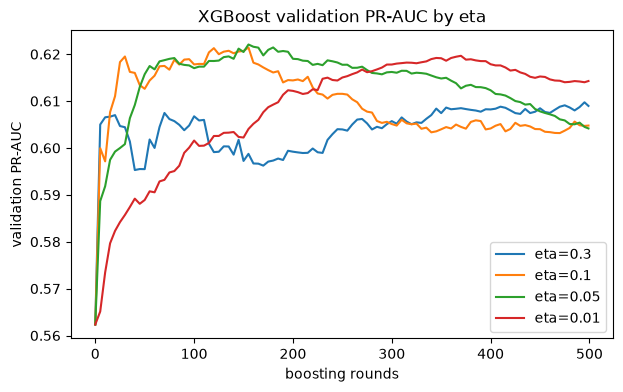

,params,best_val_aucpr,num_iter
2,eta=0.05,0.62206,155
1,eta=0.1,0.62142,155
3,eta=0.01,0.61965,370
0,eta=0.3,0.60973,495


In [69]:
scores = {}

for eta in [0.3, 0.1, 0.05, 0.01]:
    model, df_score = train_xgb(eta=eta, num_boost_round=500)
    scores['eta=%s' % eta] = df_score

plot_scores(scores, 'XGBoost validation PR-AUC by eta')
best_of(scores)

In [70]:
xgb_eta = float(best_of(scores).iloc[0].params.split('=')[1])
xgb_eta

0.05

### Tuning `max_depth`

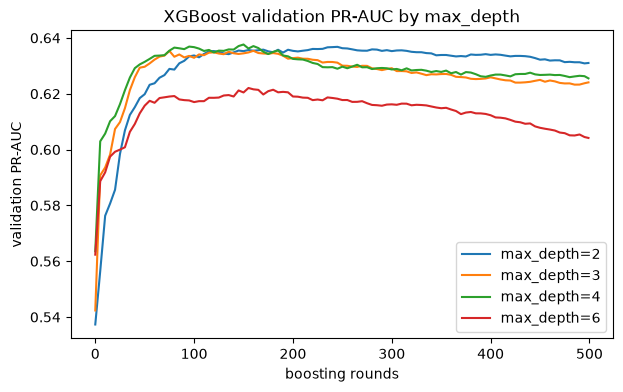

,params,best_val_aucpr,num_iter
2,max_depth=4,0.63764,150
0,max_depth=2,0.63680,245
1,max_depth=3,0.63538,160
3,max_depth=6,0.62206,155


In [71]:
scores = {}

for depth in [2, 3, 4, 6]:
    model, df_score = train_xgb(eta=xgb_eta, max_depth=depth, num_boost_round=500)
    scores['max_depth=%s' % depth] = df_score

plot_scores(scores, 'XGBoost validation PR-AUC by max_depth')
best_of(scores)

In [72]:
xgb_max_depth = int(best_of(scores).iloc[0].params.split('=')[1])
xgb_max_depth

4

### Tuning `min_child_weight`

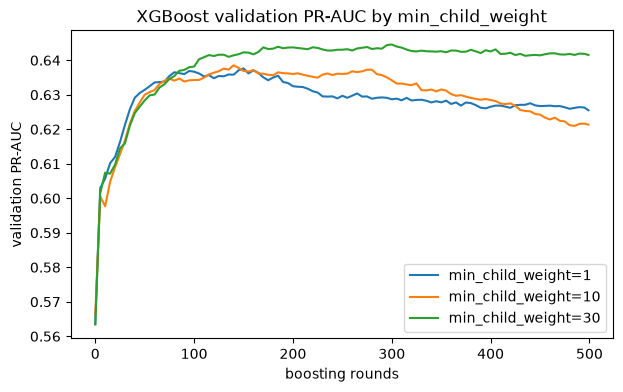

,params,best_val_aucpr,num_iter
2,min_child_weight=30,0.64457,300
1,min_child_weight=10,0.63855,140
0,min_child_weight=1,0.63764,150


In [73]:
scores = {}

for w in [1, 10, 30]:
    model, df_score = train_xgb(eta=xgb_eta, max_depth=xgb_max_depth,
                                min_child_weight=w, num_boost_round=500)
    scores['min_child_weight=%s' % w] = df_score

plot_scores(scores, 'XGBoost validation PR-AUC by min_child_weight')
best_of(scores)

In [74]:
best = best_of(scores).iloc[0]
xgb_min_child_weight = int(best.params.split('=')[1])
xgb_num_boost_round = int(best.num_iter) + 1

xgb_eta, xgb_max_depth, xgb_min_child_weight, xgb_num_boost_round

(0.05, 4, 30, 301)

In [75]:
model_xgb, _ = train_xgb(eta=xgb_eta, max_depth=xgb_max_depth,
                         min_child_weight=xgb_min_child_weight,
                         num_boost_round=xgb_num_boost_round)
y_pred_xgb = model_xgb.predict(dval)

### Feature importance from XGBoost (gain)

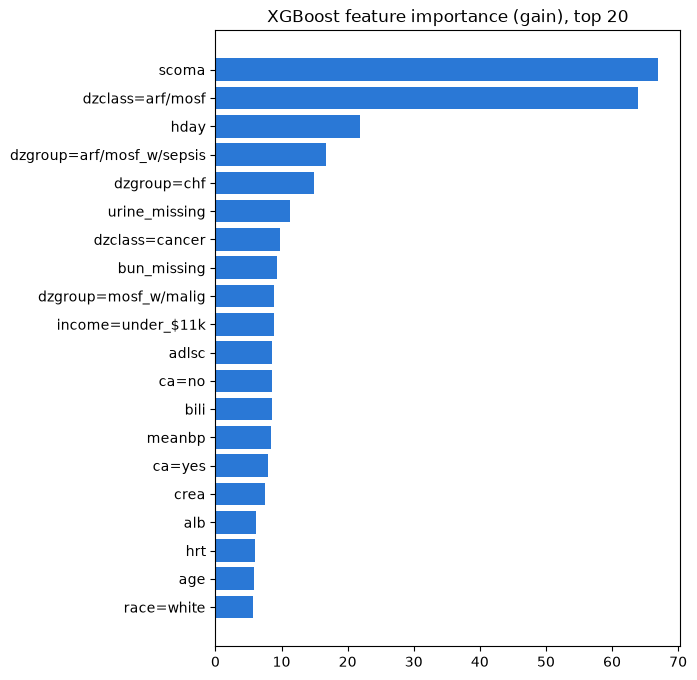

In [76]:
importance = pd.Series(model_xgb.get_score(importance_type='gain')).sort_values()

plt.figure(figsize=(6, 8))
plt.barh(importance.index[-20:], importance.values[-20:], color=BLUE)
plt.title('XGBoost feature importance (gain), top 20')
plt.show()

### Notes

* **Decision tree:** `max_depth` and `min_samples_leaf` control overfitting.
* **Random forest:** more trees help until about 70, after which the validation PR-AUC flattens at about 0.62.
* **XGBoost:** a smaller `eta` needs more rounds but generalizes better. We pick the number of rounds where the validation PR-AUC peaks. The best settings were `eta=0.05`, `max_depth=4`, `min_child_weight=30` and about 300 rounds: a shallow, heavily regularized model.
* **XGBoost importance (gain)** agrees with the EDA: `scoma`, the diagnosis (`dzclass=arf/mosf`, `dzgroup`) and `hday` come first.
* The tuned values are read from the score tables, so re-running the notebook gives the same choices.

## 10. Selecting the best model

### Comparing the models on the validation set

We also add the **SUPPORT benchmark** (`1 - surv2m`, the original study's prognosis model) as a reference.

In [77]:
from sklearn.metrics import brier_score_loss

results = []
for name, y_pred in [('logistic regression', y_pred_lr),
                     ('decision tree', y_pred_dt),
                     ('random forest', y_pred_rf),
                     ('xgboost', y_pred_xgb),
                     ('SUPPORT benchmark (1 - surv2m)', benchmark_val)]:
    results.append((name,
                    average_precision_score(y_val, y_pred),
                    roc_auc_score(y_val, y_pred),
                    brier_score_loss(y_val, y_pred)))

df_results = pd.DataFrame(results, columns=['model', 'pr_auc', 'roc_auc', 'brier'])
df_results.sort_values('pr_auc', ascending=False).round(3)

,model,pr_auc,roc_auc,brier
4,SUPPORT benchmark (1 - surv2m),0.709,0.857,0.139
3,xgboost,0.645,0.822,0.140
2,random forest,0.628,0.821,0.143
0,logistic regression,0.625,0.817,0.142
1,decision tree,0.570,0.782,0.153


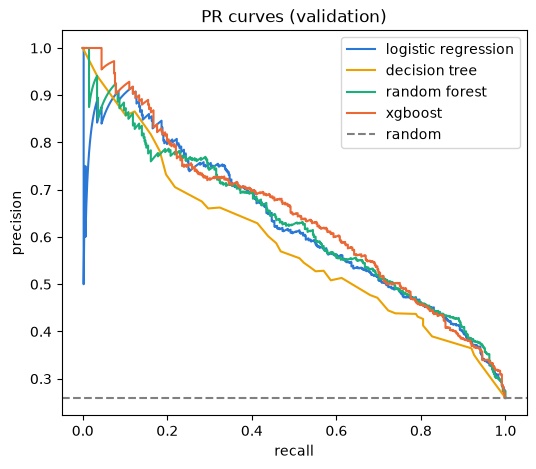

In [78]:
plt.figure(figsize=(6, 5))
for (name, y_pred), color in zip([('logistic regression', y_pred_lr), ('decision tree', y_pred_dt),
                                  ('random forest', y_pred_rf), ('xgboost', y_pred_xgb)],
                                 [BLUE, '#eda100', '#1baf7a', ORANGE]):
    prec, rec, _ = precision_recall_curve(y_val, y_pred)
    plt.plot(rec, prec, color=color, label=name)

plt.axhline(y_val.mean(), color='grey', linestyle='--', label='random')
plt.xlabel('recall'); plt.ylabel('precision'); plt.title('PR curves (validation)')
plt.legend()
plt.show()

In [79]:
val_preds = {'logistic regression': y_pred_lr, 'decision tree': y_pred_dt,
             'random forest': y_pred_rf, 'xgboost': y_pred_xgb}

best_model = df_results.iloc[:4].sort_values('pr_auc', ascending=False).iloc[0].model
best_model

'xgboost'

### Training the final model on full_train and testing it

We retrain the best model on `df_full_train` (train + validation) and evaluate it **once** on the test set.

In [80]:
y_full_train = df_full_train.hospdead.values
df_full_train_X = df_full_train.drop(columns='hospdead')

medians_full = df_full_train_X[numerical].median()

if best_model == 'logistic regression':
    dv_final, medians_final, final_model = train(df_full_train_X, y_full_train, C=C)
    y_pred_test = predict(df_test, dv_final, medians_final, final_model)
else:
    dv_final = DictVectorizer(sparse=False)
    X_full_train = dv_final.fit_transform(prepare_dicts(df_full_train_X, medians_full))
    X_test = dv_final.transform(prepare_dicts(df_test, medians_full))

    if best_model == 'xgboost':
        features = list(dv_final.get_feature_names_out())
        dfulltrain = xgb.DMatrix(X_full_train, label=y_full_train, feature_names=features)
        dtest = xgb.DMatrix(X_test, feature_names=features)
        xgb_params = {
            'eta': xgb_eta, 'max_depth': xgb_max_depth, 'min_child_weight': xgb_min_child_weight,
            'objective': 'binary:logistic', 'eval_metric': 'aucpr',
            'nthread': 8, 'seed': 1, 'verbosity': 1,
        }
        final_model = xgb.train(xgb_params, dfulltrain, num_boost_round=xgb_num_boost_round)
        y_pred_test = final_model.predict(dtest)
    elif best_model == 'random forest':
        final_model = RandomForestClassifier(n_estimators=200, max_depth=rf_max_depth,
                                             min_samples_leaf=rf_min_samples_leaf,
                                             random_state=1, n_jobs=-1)
        final_model.fit(X_full_train, y_full_train)
        y_pred_test = final_model.predict_proba(X_test)[:, 1]
    else:
        final_model = DecisionTreeClassifier(max_depth=dt_max_depth,
                                             min_samples_leaf=dt_min_samples_leaf, random_state=1)
        final_model.fit(X_full_train, y_full_train)
        y_pred_test = final_model.predict_proba(X_test)[:, 1]

print('%s on TEST' % best_model)
print('  PR-AUC  %.3f' % average_precision_score(y_test, y_pred_test))
print('  ROC AUC %.3f' % roc_auc_score(y_test, y_pred_test))
print('  Brier   %.3f' % brier_score_loss(y_test, y_pred_test))
print('SUPPORT benchmark on TEST')
print('  PR-AUC  %.3f' % average_precision_score(y_test, benchmark_test))
print('  ROC AUC %.3f' % roc_auc_score(y_test, benchmark_test))

xgboost on TEST
  PR-AUC  0.624
  ROC AUC 0.813
  Brier   0.143
SUPPORT benchmark on TEST
  PR-AUC  0.644
  ROC AUC 0.821


### Choosing the decision threshold

We want to flag most of the patients who will die. On the **validation** predictions we pick the highest threshold that still gives a **recall ≥ 0.80**, then check what it gives on the test set.

In [81]:
df_scores = pr_dataframe(y_val, val_preds[best_model])
threshold = df_scores[df_scores.recall >= 0.8].threshold.max()
print('threshold chosen on validation: %.2f' % threshold)

df_scores = pr_dataframe(y_test, y_pred_test)
df_scores[np.isclose(df_scores.threshold, threshold)][['threshold', 'tp', 'fp', 'fn', 'tn', 'precision', 'recall']].round(3)

threshold chosen on validation: 0.20


,threshold,tp,fp,fn,tn,precision,recall
20,0.2,376,431,96,918,0.466,0.797


### Notes

* **XGBoost** had the best validation PR-AUC (0.645), ahead of random forest (0.628), logistic regression (0.625) and the decision tree (0.570). The three best models are close, so logistic regression is a strong, interpretable baseline.
* On the **test set** XGBoost gets PR-AUC ≈ 0.62 and ROC AUC ≈ 0.81, close to its validation score, so the tuning did not overfit the validation set much.
* The **SUPPORT benchmark** is still better (test PR-AUC ≈ 0.64, ROC AUC ≈ 0.82). It is a published model, built from the APS physiology score using more detailed day-3 data, so getting close to it from the raw variables is a reasonable result. Feeding `aps`/`sps` in as features could close the gap, but only if those scores are available at prediction time.
* With a recall target of 0.80, roughly one in two flagged patients actually dies (precision ≈ 0.47 on test). That is acceptable for a screening tool that triggers a review, not an automatic decision.
* Next step: move `prepare_dicts`, the training and the chosen parameters into `train.py`, save the model with `pickle`, and serve it with `predict.py` (lesson 5).